In [ ]:
#1. Dataset Description


import pandas as pd

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 120)

path = "Project_train.csv"

df = pd.read_csv(path)

print(df.head(20))

    Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID       Customer Name      Segment  \
0        1  CA-2017-152156  08/11/2017  11/11/2017    Second Class    CG-12520         Claire Gute     Consumer   
1        2  CA-2017-152156  08/11/2017  11/11/2017    Second Class    CG-12520         Claire Gute     Consumer   
2        3  CA-2017-138688  12/06/2017  16/06/2017    Second Class    DV-13045     Darrin Van Huff    Corporate   
3        4  US-2016-108966  11/10/2016  18/10/2016  Standard Class    SO-20335      Sean O'Donnell     Consumer   
4        5  US-2016-108966  11/10/2016  18/10/2016  Standard Class    SO-20335      Sean O'Donnell     Consumer   
5        6  CA-2015-115812  09/06/2015  14/06/2015  Standard Class    BH-11710     Brosina Hoffman     Consumer   
6        7  CA-2015-115812  09/06/2015  14/06/2015  Standard Class    BH-11710     Brosina Hoffman     Consumer   
7        8  CA-2015-115812  09/06/2015  14/06/2015  Standard Class    BH-11710  

In [4]:
print(df.info(),df.shape, df.dtypes,df.columns)


<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [ ]:
#2. Central Tendency and Dispersion Analysis

sales = df['Sales'].dropna()

mean = sales.mean()
median = sales.median()
mode = sales.mode()[0]
std = sales.std()
variance = sales.var()
Q1 = sales.quantile(0.25)
Q3 = sales.quantile(0.75)
IQR = Q3 - Q1



stats_table = pd.DataFrame({
    'Feature': ['Sales'],
    'Mean': [mean],
    'Median': [median],
    'Mode': [mode],
    'Variance': [variance],
    'Std Dev': [std],
    'IQR': [IQR],
  
})

print(stats_table) 



  Feature        Mean  Median   Mode       Variance     Std Dev      IQR
0   Sales  230.769059   54.49  12.96  392692.572239  626.651875  193.357


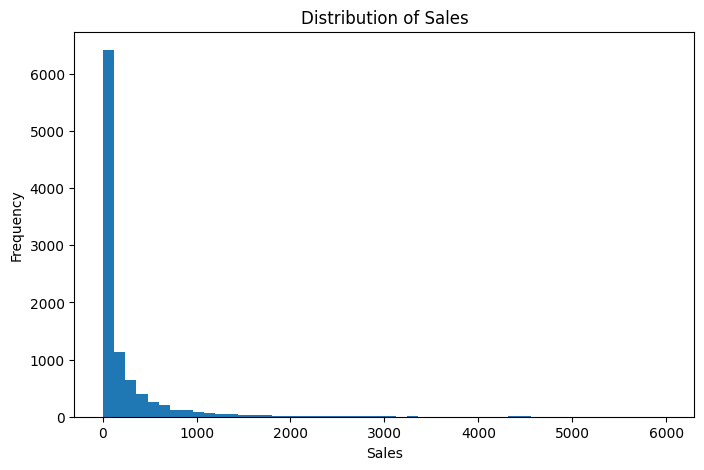

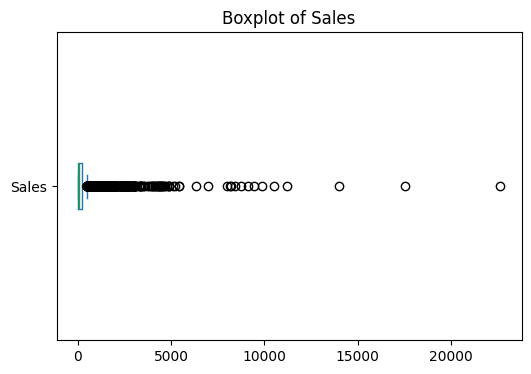

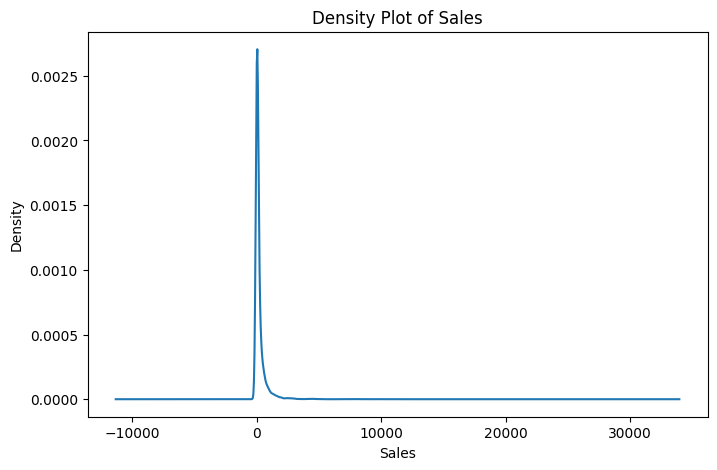

Lower Bound: -272.7875000000001
Upper Bound: 500.6405000000001
Number of Outliers: 1145


In [ ]:
#3. Distribution and Shape


import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sales.plot(kind="hist", bins=50, range=(0, 6000))
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()


plt.figure(figsize=(6,4))
sales.plot(kind="box", vert=False)
plt.title("Boxplot of Sales")
plt.show()


plt.figure(figsize=(8,5))
sales.plot(kind="density")
plt.title("Density Plot of Sales")
plt.xlabel("Sales")
plt.ylabel("Density")
plt.show()

#Outliers

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


outliers = df[(df['Sales'] < lower_bound) | (df['Sales'] > upper_bound)]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", outliers.shape[0])

C:\Users\USER\AppData\Local\Temp\ipykernel_5712\3565435758.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


Categorical Columns:
 Index(['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country',
       'City', 'State', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name'],
      dtype='str')

Column: Order ID
Order ID
CA-2018-100111    14
CA-2018-157987    12
US-2017-108504    11
CA-2017-165330    11
CA-2016-131338    10
                  ..
CA-2017-104983     1
CA-2017-160234     1
CA-2016-155635     1
US-2015-114377     1
CA-2017-125920     1
Name: count, Length: 4922, dtype: int64

Column: Order Date
Order Date
05/09/2017    38
10/11/2017    35
01/12/2018    34
02/12/2018    34
09/12/2018    33
              ..
14/04/2016     1
28/01/2016     1
10/06/2015     1
18/06/2015     1
09/05/2016     1
Name: count, Length: 1230, dtype: int64

Column: Ship Date
Ship Date
26/09/2018    34
06/12/2018    32
16/12/2016    31
15/09/2018    30
12/12/2018    30
              ..
03/03/2015     1
23/06/2017     1
31/01/2016     1
06/04/2018     

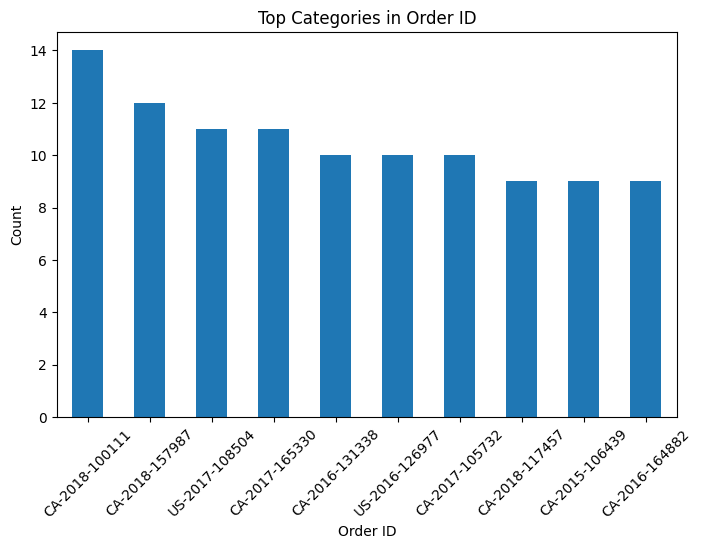

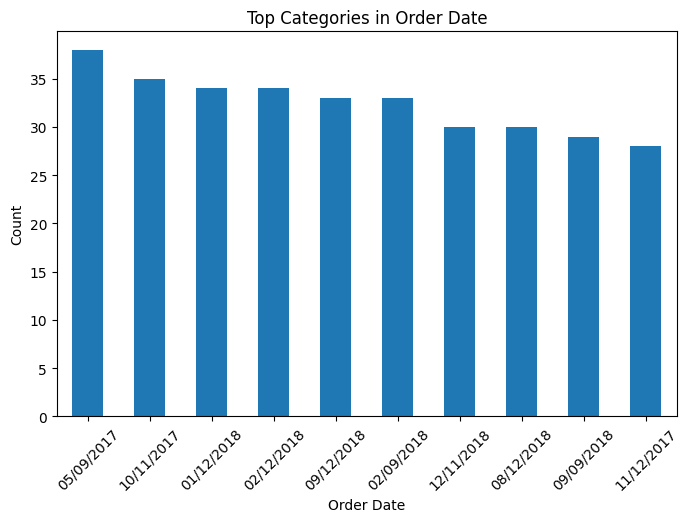

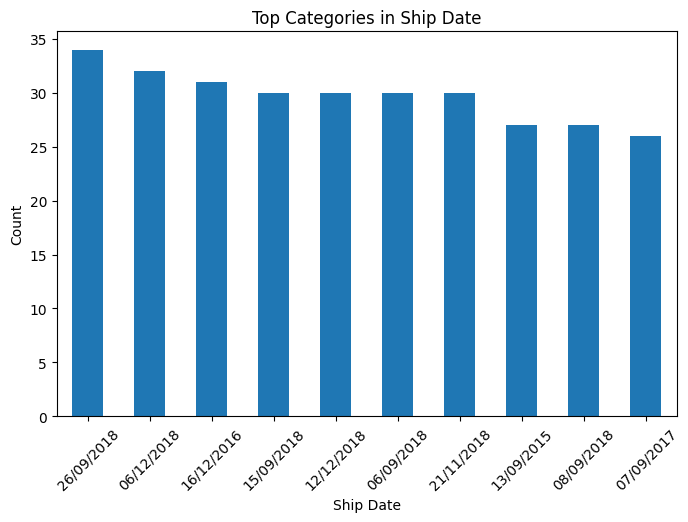

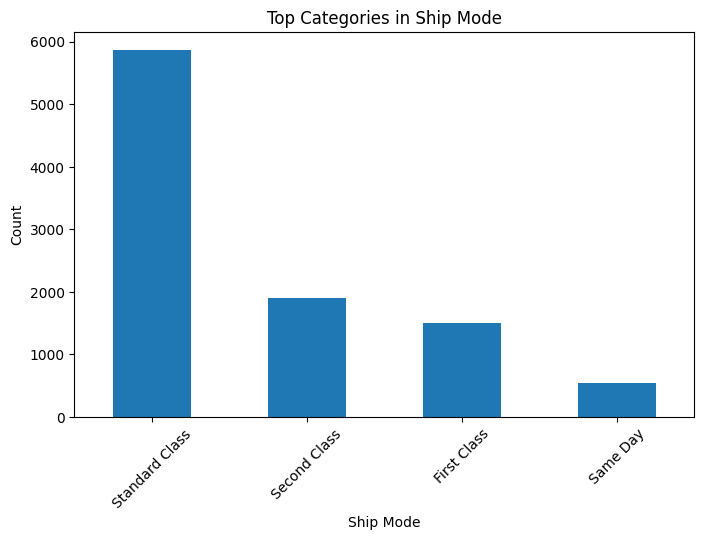

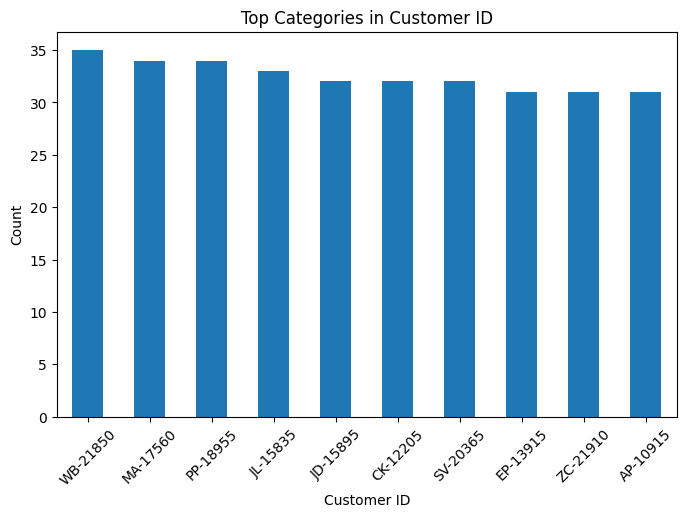

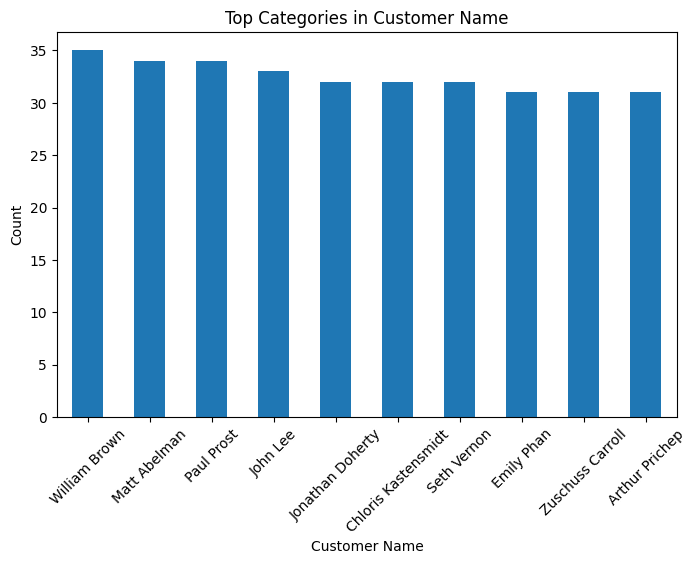

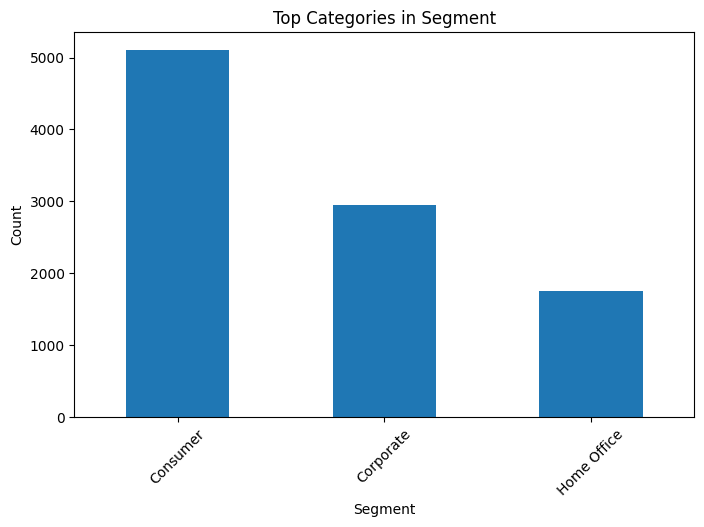

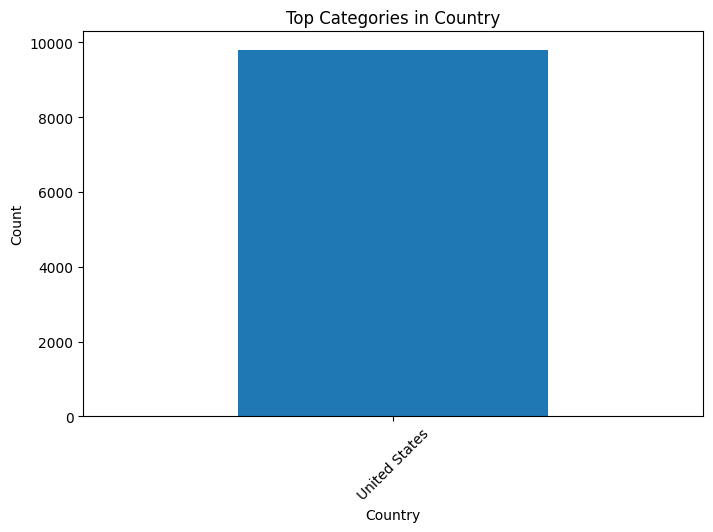

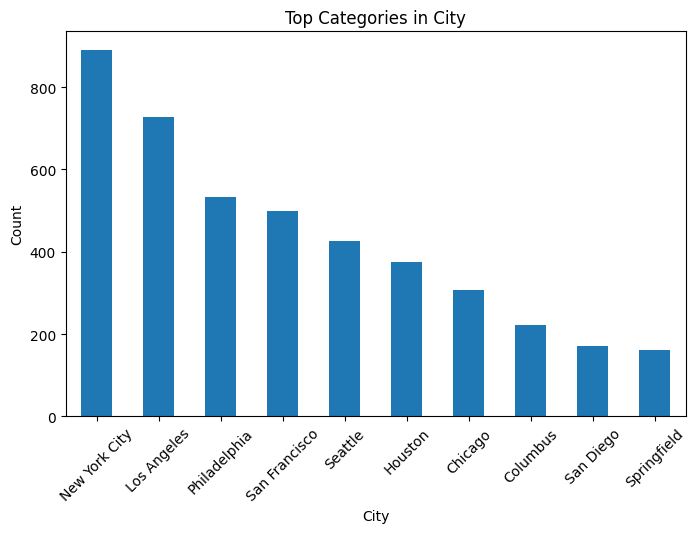

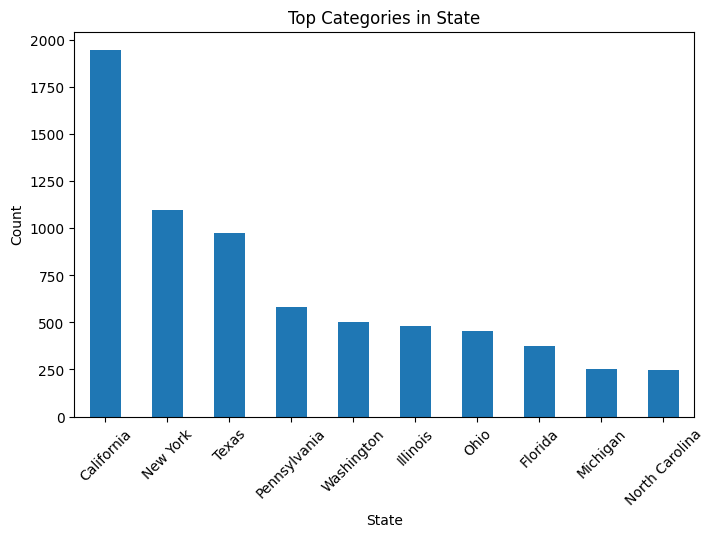

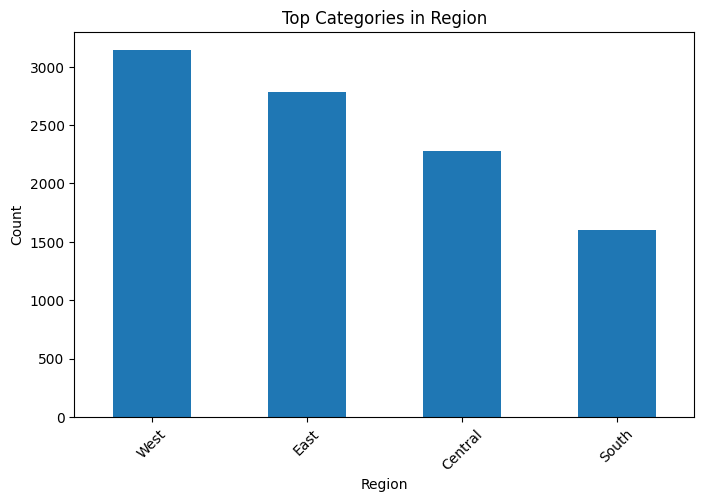

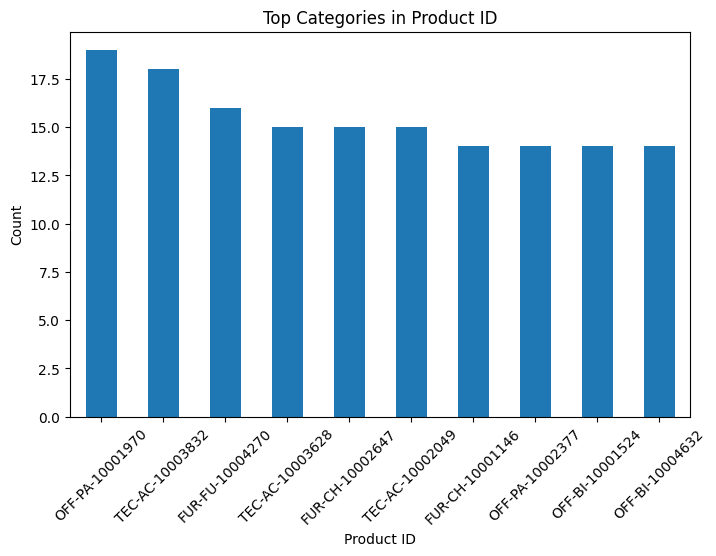

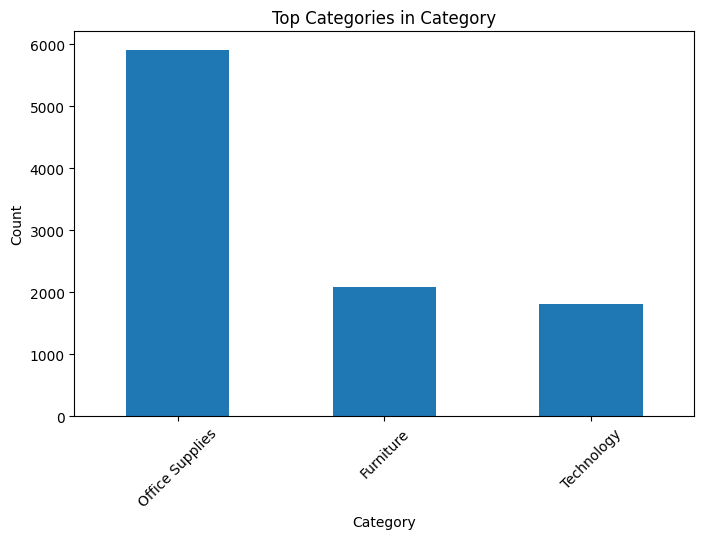

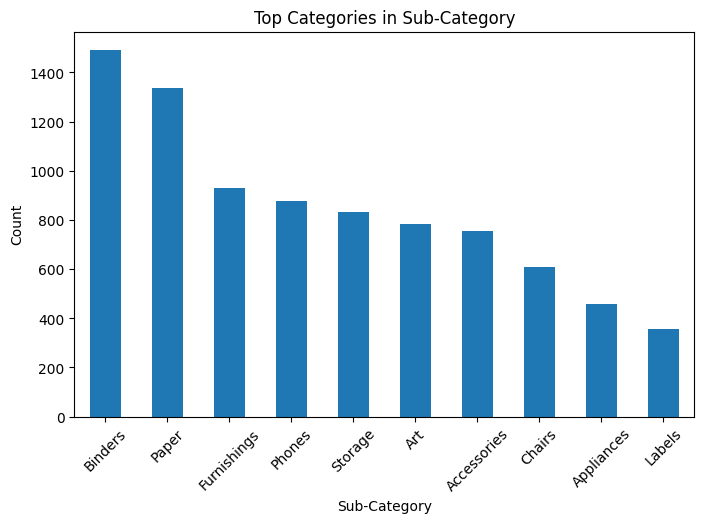

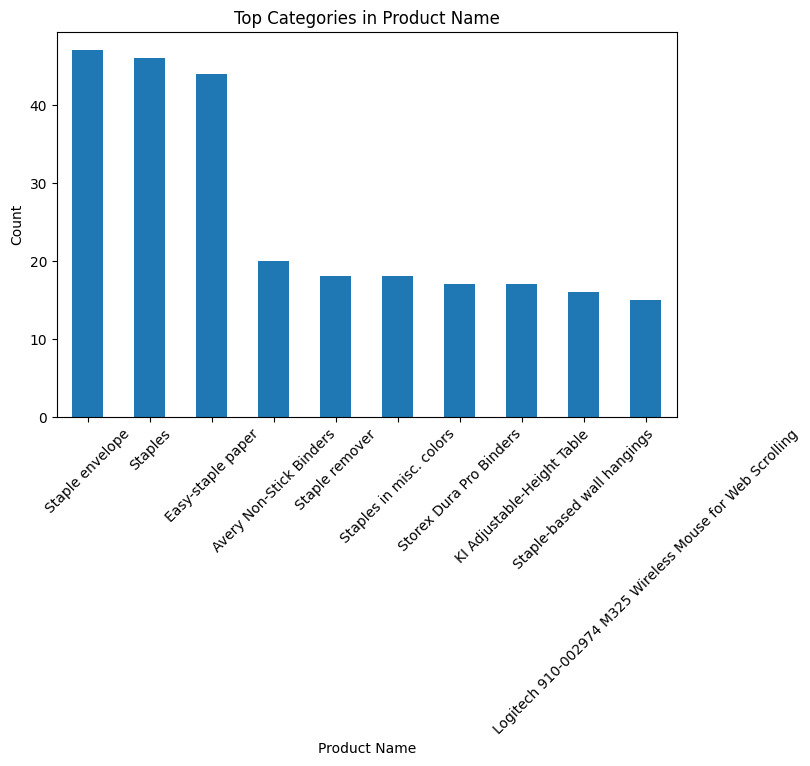

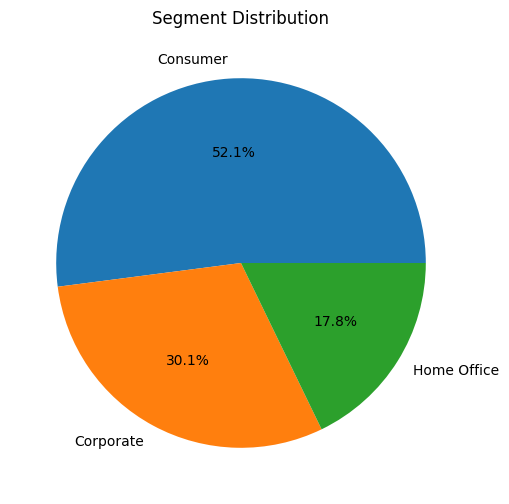

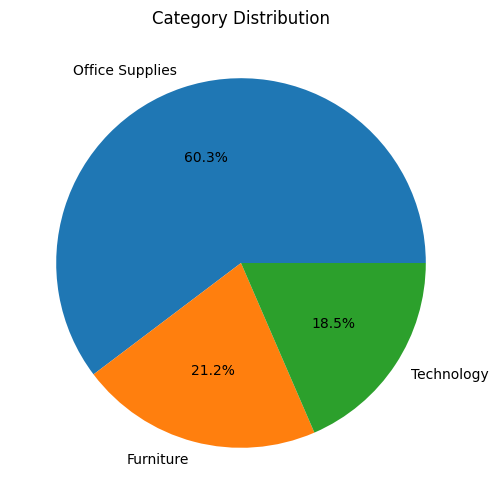

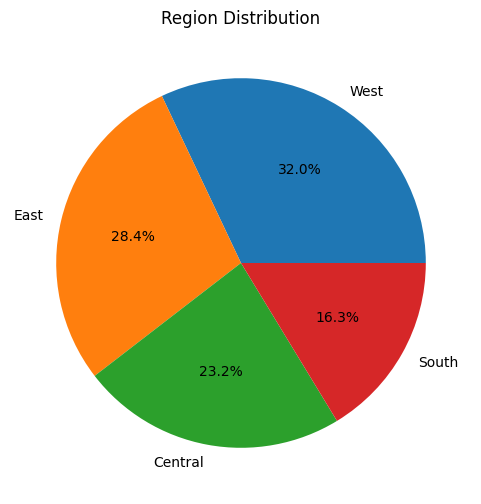

In [ ]:
#4. Categorical Variable Analysis

cat_cols = df.select_dtypes(include=['object']).columns
print("Categorical Columns:\n", cat_cols)


for col in cat_cols:
    print("\n====================")
    print("Column:", col)
    print(df[col].value_counts())


for col in cat_cols:
    plt.figure(figsize=(8,5))
    df[col].value_counts().head(10).plot(kind='bar')
    plt.title(f"Top Categories in {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()


important_cols = ['Segment', 'Category', 'Region']

for col in important_cols:
    if col in df.columns:
        plt.figure(figsize=(6,6))
        df[col].value_counts().plot(kind='pie', autopct='%1.1f%%')
        plt.title(f"{col} Distribution")
        plt.ylabel("")
        plt.show()

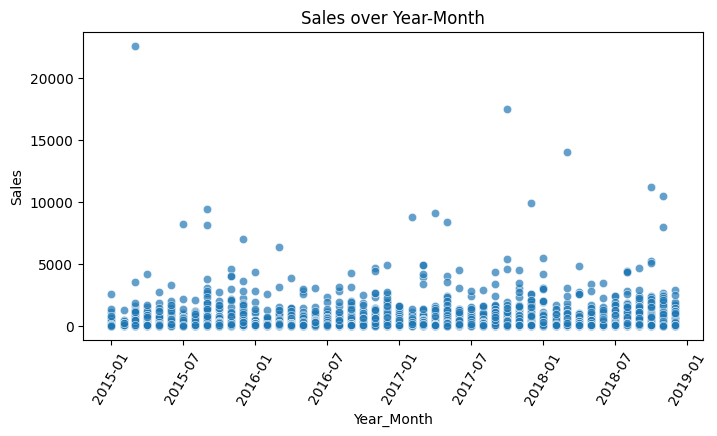

In [ ]:
#5. Relationships Between Variables    
# (converting Order Date to year-month format, setting each date to the first day of the month in the Year_Month column.)

import seaborn as sns
df['Year_Month'] = df['Order Date'].dt.to_period('M').dt.to_timestamp()

plt.figure(figsize=(8,4))
sns.scatterplot(
    data=df,
    x='Year_Month',
    y='Sales',
    alpha=0.7
)

plt.title('Sales over Year-Month')
plt.xlabel('Year_Month')
plt.ylabel('Sales')

plt.xticks(rotation=60) 
plt.show()

In [ ]:
#6. Data Quality Assessment

# Percentage of missing values
print(" Missing Value Percentage:\n")
print((df.isna().mean() * 100).sort_values(ascending=False))

# Count of missing values
print("\n Missing Value Count:\n")
print(df.isna().sum().sort_values(ascending=False))

# Total duplicate rows
print("\n Total Duplicate Rows:")
print(df.duplicated().sum())

# Percentage of duplicate rows
print("\n Duplicate Rows Percentage:")
print(df.duplicated().mean() * 100)



 Missing Value Percentage:

Postal Code      0.112245
Order ID         0.000000
Row ID           0.000000
Ship Date        0.000000
Ship Mode        0.000000
Customer ID      0.000000
Customer Name    0.000000
Segment          0.000000
Country          0.000000
City             0.000000
Order Date       0.000000
State            0.000000
Region           0.000000
Product ID       0.000000
Category         0.000000
Sub-Category     0.000000
Product Name     0.000000
Sales            0.000000
Order Year       0.000000
Order Month      0.000000
Order Day        0.000000
Ship Year        0.000000
Ship Month       0.000000
Ship Day         0.000000
Shipping Days    0.000000
Year-Month       0.000000
Year_Month       0.000000
dtype: float64

 Missing Value Count:

Postal Code      11
Order ID          0
Row ID            0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
Order Date        0
State      

In [ ]:
# Unusual values 
# Checking negative or very large shipping days

df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)
df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days

print("\nShipping Days Summary:")
print(df['Shipping Days'].describe())

# Negative values
print("\nNegative Shipping Days:")

Negative_ship_days= df[df['Shipping Days'] < 0]

if  len(Negative_ship_days) == 0:
    print("No unusual values found in shipping days")
else:
    print("Unusual values(Negative_ship_days):", Negative_ship_days)


Shipping Days Summary:
count    9800.000000
mean        3.961122
std         1.749614
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Shipping Days, dtype: float64

Negative Shipping Days:
No unusual values found in shipping days
